# Lung Incomplete_Cases — pan-cancer Hist2Pheno

All **20** Xenium Incomplete_Cases (StarDist-all maps; no TLS / SRI / TNI).
**Top 5** are ranked by matched-cell **L2 macro AUROC** (17 slides have
`*_matched_features.h5ad`). TILD028LA / TILD049MA / VUHD038 have no matched GT
and are last.

Checkpoint: `data/PanCancer/result_all_spatial/cross_dataset_cv/D_emph_L2_spatial_pancancer/best_mlp_gpu.pt`

```bash
bash code/External_val/Lung_Incomplete/demo.sh rank
bash code/External_val/Lung_Incomplete/demo.sh status
```


In [1]:
from operator import truediv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "External_val"))

import unlabeled_external as ue

COHORT = "Lung_Incomplete"
SAVE_FIGURES = truediv
FIGSIZE = (17.2, 12.5)
DPI = 160
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 2.0

cov = ue.coverage(COHORT)
rank = ue.rank_lung_incomplete(compute=False)
samples = ue.viz_samples(COHORT)
top5 = samples[:5]
rest = samples[5:]
print(f"{COHORT}: {len(cov)} slides; plot order {len(samples)} (top 5 first)")
print("top5", top5)
print("rest", rest)
if rank.empty:
    print("ranks missing — run: bash code/External_val/Lung_Incomplete/demo.sh rank")
else:
    cols = [c for c in (
        "rank_ds", "n_ds", "sample", "n_matched",
        "macro_auc_L1", "macro_auc_L12", "macro_auc_L2", "acc_L2",
    ) if c in rank.columns]
    display(Markdown("### Matched-cell ranks (L2 AUROC). Top 5 are plotted first."))
    display(rank[cols])


Lung_Incomplete: 20 slides; plot order 20 (top 5 first)
top5 ['TILD111LA', 'TILD113LA', 'VUILD105MA1', 'VUILD141MA', 'TILD117MA2']
rest ['VUILD49LA', 'VUILD48LA1', 'VUILD104MA2', 'VUILD58MA', 'TILD299MA', 'TILD315MA', 'VUHD090', 'VUHD049', 'TILD130LA', 'TILD167LA', 'TILD080LA', 'VUILD142MA', 'TILD028LA', 'TILD049MA', 'VUHD038']


### Matched-cell ranks (L2 AUROC). Top 5 are plotted first.

,rank_ds,n_ds,sample,n_matched,macro_auc_L1,macro_auc_L12,macro_auc_L2,acc_L2
0,1.0,17,TILD111LA,10219,0.507891,0.540381,0.549158,0.259517
1,2.0,17,TILD113LA,6039,0.543672,0.556599,0.541161,0.134956
2,3.0,17,VUILD105MA1,10848,0.542688,0.538619,0.528816,0.092552
3,4.0,17,VUILD141MA,13243,0.489956,0.494358,0.508105,0.071887
4,5.0,17,TILD117MA2,5568,0.501731,0.509432,0.505596,0.063937
5,6.0,17,VUILD49LA,8058,0.484357,0.492406,0.504444,0.160834
6,7.0,17,VUILD48LA1,8431,0.494408,0.488684,0.497828,0.182659
7,8.0,17,VUILD104MA2,20924,0.498513,0.503675,0.497083,0.121822
8,9.0,17,VUILD58MA,3218,0.472811,0.483220,0.494757,0.126476
9,10.0,17,TILD299MA,9643,0.509043,0.479832,0.493278,0.088458


## TILD113LA, VUILD105MA1

### TILD113LA  L2 AUROC=0.541  #2/17 Incomplete matched

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/incomplete_lung/figures/TILD113LA_spatial_L1_L12_L2.png


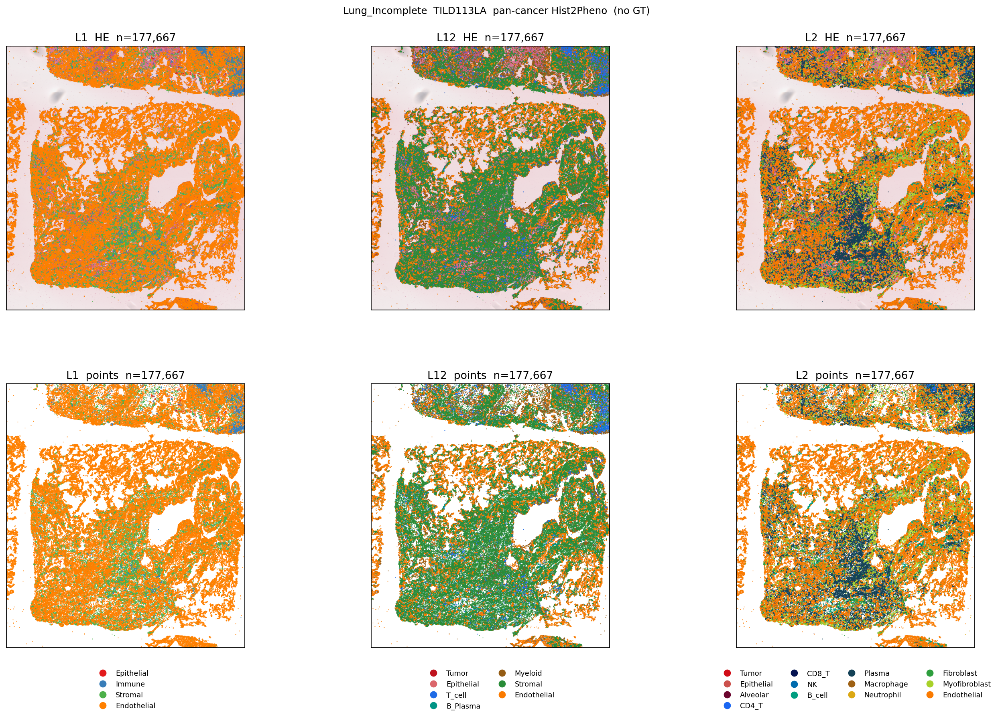

### VUILD105MA1  L2 AUROC=0.529  #3/17 Incomplete matched

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/incomplete_lung/figures/VUILD105MA1_spatial_L1_L12_L2.png


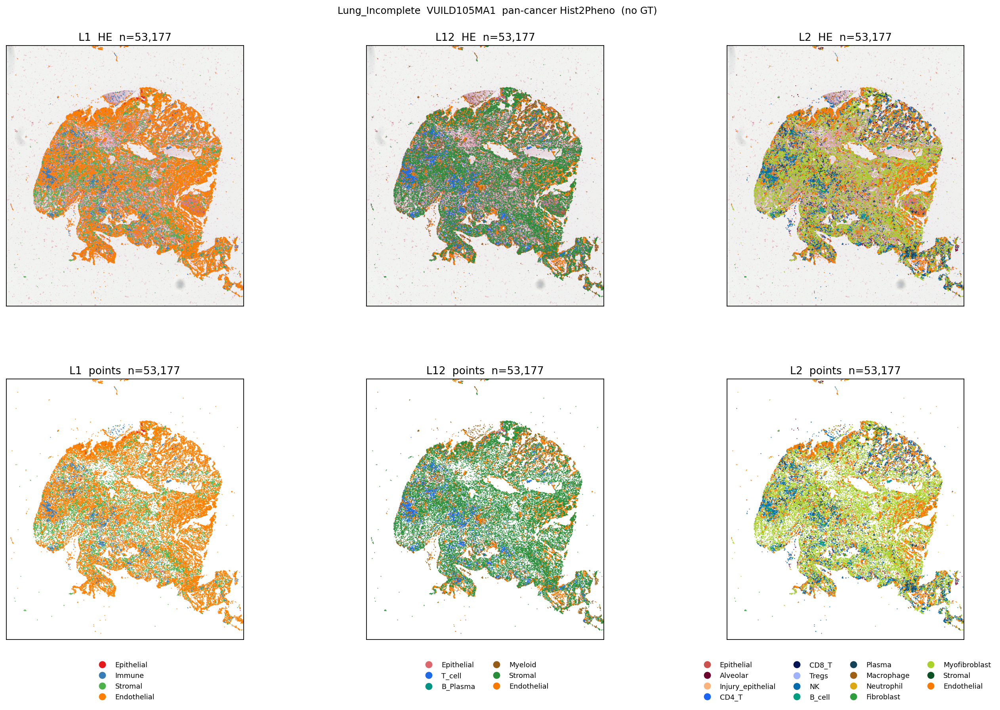

In [2]:
focus = ["TILD113LA", "VUILD105MA1"]


def _rank_title(sample: str) -> str:
    if rank.empty or "sample" not in rank.columns:
        return sample
    hit = rank.loc[rank["sample"].astype(str) == str(sample)]
    if hit.empty:
        return f"{sample}  (no matched GT)"
    rank_ds = hit.iloc[0]["rank_ds"]
    if rank_ds != rank_ds:
        return f"{sample}  (no matched GT)"
    r = hit.iloc[0]
    return (
        f"{sample}  L2 AUROC={float(r.macro_auc_L2):.3f}  "
        f"#{int(r.rank_ds)}/{int(r.n_ds)} Incomplete matched"
    )


def _draw(sample: str) -> None:
    pred = ue.pred_h5ad(ue._cohort(COHORT), sample)
    display(Markdown(f"### {_rank_title(sample)}"))
    if not pred.is_file():
        print("missing pred", sample, "— run demo.sh predict")
        return
    figs = ue.plot_spatial(
        COHORT,
        [sample],
        save=SAVE_FIGURES,
        figsize=FIGSIZE,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        he_max_side=HE_MAX_SIDE,
        marker_px=MARKER_PX,
    )
    for fig in figs:
        display(fig)
        plt.close(fig)


display(Markdown("## TILD113LA, VUILD105MA1"))
for sample in focus:
    _draw(sample)


### TILD113LA  legend

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/incomplete_lung/figures/TILD113LA_legend.pdf


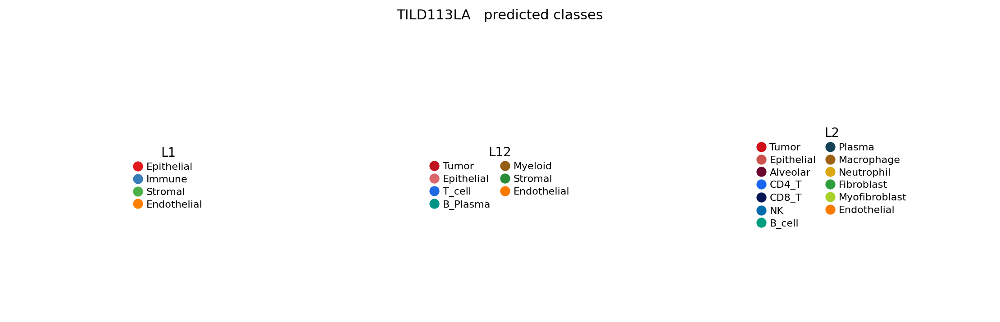

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/incomplete_lung/figures/TILD113LA_legend_L1.pdf
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/incomplete_lung/figures/TILD113LA_legend_L12.pdf
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/incomplete_lung/figures/TILD113LA_legend_L2.pdf


### VUILD105MA1  legend

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/incomplete_lung/figures/VUILD105MA1_legend.pdf


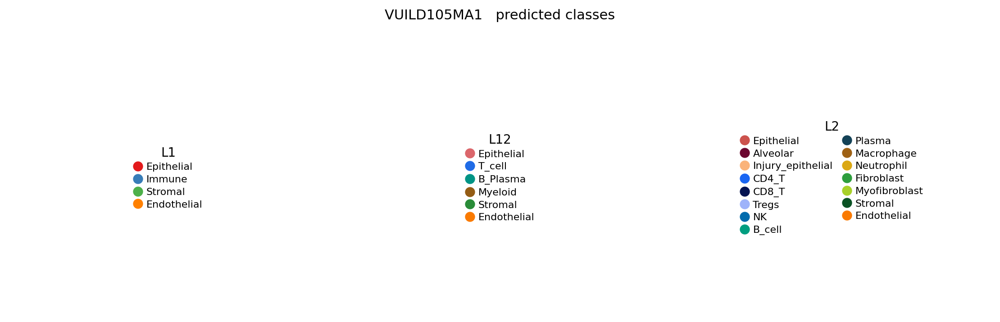

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/incomplete_lung/figures/VUILD105MA1_legend_L1.pdf
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/incomplete_lung/figures/VUILD105MA1_legend_L12.pdf
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/incomplete_lung/figures/VUILD105MA1_legend_L2.pdf


In [3]:
from matplotlib.lines import Line2D
import anndata as ad

# One L1 / L12 / L2 legend per sample (the two spatial maps above).
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["pdf.use14corefonts"] = True

cohort = ue._cohort(COHORT)
palettes = ue._palettes()
FIG_DIR = cohort.pred_parent / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def _legend_handles(palette, names):
    return [
        Line2D(
            [0],
            [0],
            linestyle="none",
            marker="o",
            markersize=8,
            markerfacecolor=palette.get(n, (0.5, 0.5, 0.5, 1))[:3],
            markeredgecolor="none",
            label=n,
        )
        for n in names
    ]


def _present_names(adata, head):
    palette = palettes[head]
    seen = set(map(str, adata.obs[ue.OBS_COL[head]].tolist()))
    names = [n for n in palette if n in seen]
    names += sorted(seen - set(names))
    return names


for sample in focus:
    adata = ad.read_h5ad(ue.pred_h5ad(cohort, sample))
    display(Markdown(f"### {sample}  legend"))
    fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.6), dpi=200)
    for ax, head in zip(axes, ue.HEADS):
        names = _present_names(adata, head)
        ax.set_axis_off()
        ax.legend(
            handles=_legend_handles(palettes[head], names),
            loc="center",
            frameon=False,
            ncol=1 if len(names) <= 6 else 2,
            fontsize=8,
            handlelength=0.8,
            handletextpad=0.45,
            columnspacing=1.0,
            labelspacing=0.35,
            borderaxespad=0.0,
            title=head,
            title_fontsize=10,
        )
    fig.suptitle(f"{sample}   predicted classes", fontsize=11, y=0.98)
    fig.tight_layout()
    stem = FIG_DIR / f"{sample}_legend"
    fig.savefig(stem.with_suffix(".png"), dpi=300, bbox_inches="tight", facecolor="white")
    fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
    print(stem.with_suffix(".pdf"))
    display(fig)
    plt.close(fig)

    # Separate L1 / L12 / L2 PDFs for panel assembly.
    for head in ue.HEADS:
        names = _present_names(adata, head)
        ncol = 1 if len(names) <= 8 else 2
        fig_h, ax = plt.subplots(figsize=(2.8 * ncol, 0.38 * ((len(names) + ncol - 1) // ncol) + 0.7), dpi=200)
        ax.set_axis_off()
        ax.legend(
            handles=_legend_handles(palettes[head], names),
            loc="center",
            frameon=False,
            ncol=ncol,
            fontsize=8,
            handlelength=0.8,
            handletextpad=0.45,
            columnspacing=1.0,
            labelspacing=0.35,
            borderaxespad=0.0,
            title=head,
            title_fontsize=10,
        )
        stem_h = FIG_DIR / f"{sample}_legend_{head}"
        fig_h.savefig(stem_h.with_suffix(".png"), dpi=300, bbox_inches="tight", facecolor="white")
        fig_h.savefig(stem_h.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
        print(stem_h.with_suffix(".pdf"))
        plt.close(fig_h)


### TILD113LA  zoom  Plasma-rich lymphoid island  [7800:10200]×[13000:15400]  510×510 µm

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/incomplete_lung/figures/TILD113LA_ROI_HE.pdf


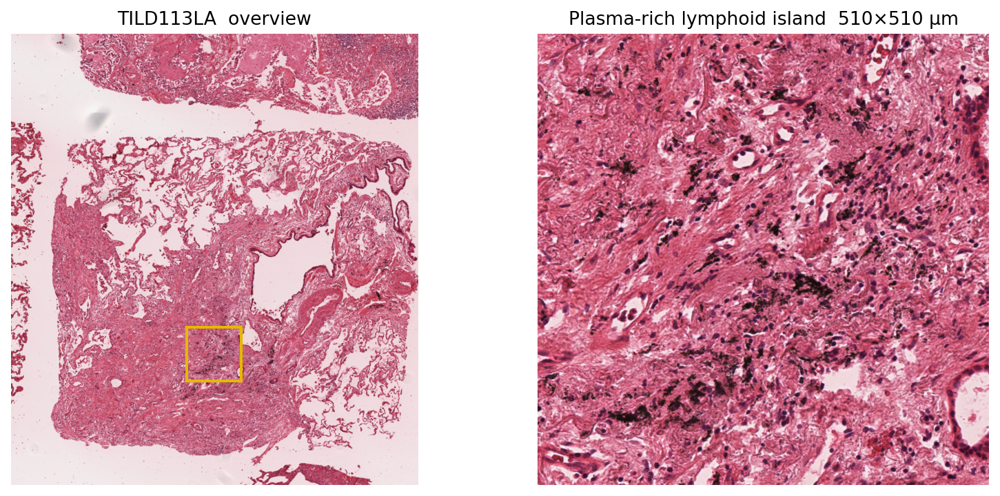

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/incomplete_lung/figures/TILD113LA_ROI_spatial_L1_L12_L2.pdf


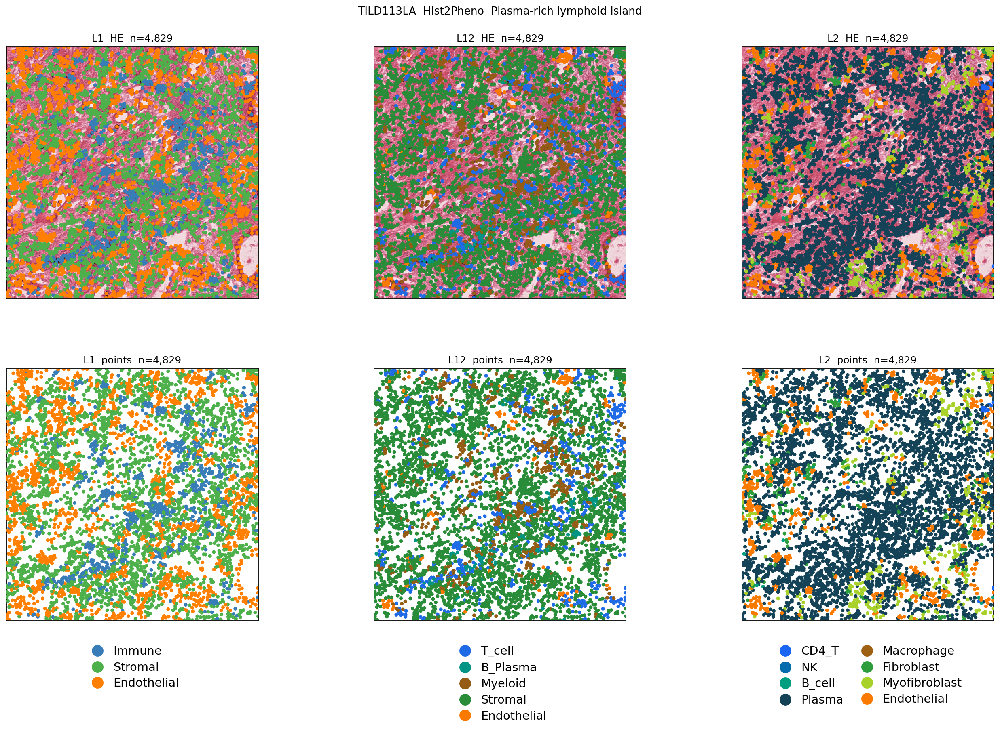

### VUILD105MA1  zoom  Airway epithelium + myofibroblast wall  [7400:11000]×[3400:6400]  765×638 µm

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/incomplete_lung/figures/VUILD105MA1_ROI_HE.pdf


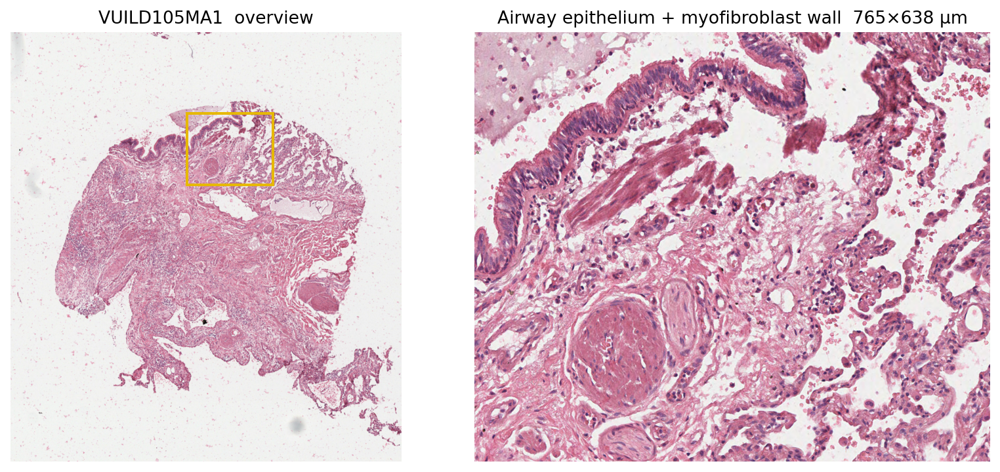

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/incomplete_lung/figures/VUILD105MA1_ROI_spatial_L1_L12_L2.pdf


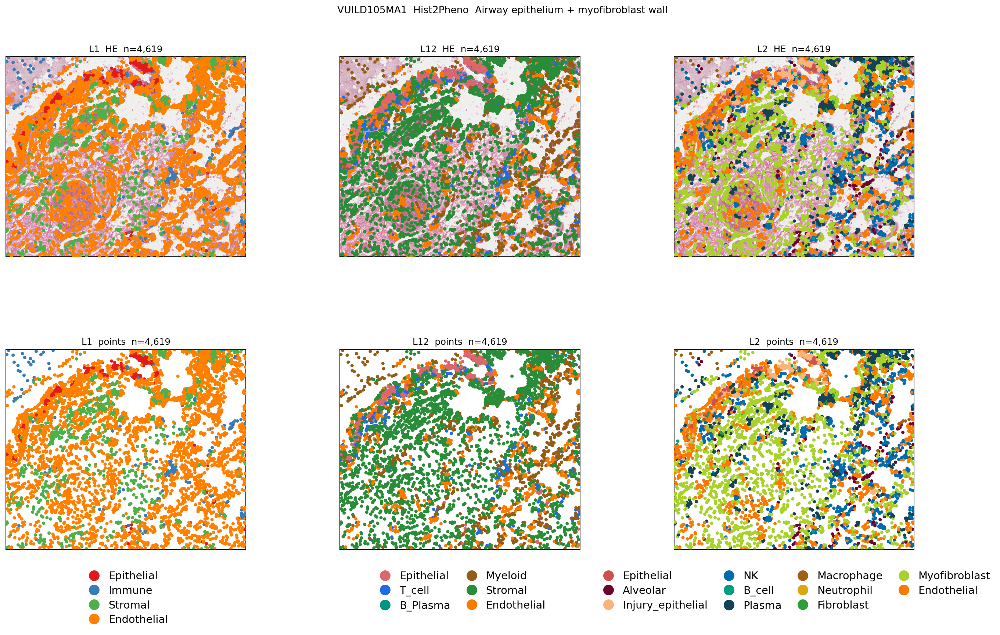

In [5]:
import anndata as ad
from matplotlib.patches import Rectangle
from panel_figures import crop_he_rectangle, plot_roi_pred_spatial

# TILD113LA ImageJ tag is 4.705882 px/µm; VUILD105MA1 uses the same Xenium-lung HE scale.
PX_PER_UM = 4705882 / 1_000_000
# ~510 µm Plasma-rich island; ~765 × 638 µm airway epithelium + fibrotic wall.
ROIS = {
    "TILD113LA": {
        "xy": (7800, 13000, 10200, 15400),
        "note": "Plasma-rich lymphoid island",
    },
    "VUILD105MA1": {
        "xy": (7400, 3400, 11000, 6400),
        "note": "Airway epithelium + myofibroblast wall",
    },
}

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["pdf.use14corefonts"] = True

cohort = ue._cohort(COHORT)
palettes = ue._palettes()
FIG_DIR = cohort.pred_parent / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

for sample, spec in ROIS.items():
    x0, y0, x1, y1 = spec["xy"]
    he = ue.he_path(cohort, sample)
    adata = ad.read_h5ad(ue.pred_h5ad(cohort, sample))
    thumb, fw, fh = ue._he_thumbnail(he, HE_MAX_SIDE)
    w_um = (x1 - x0) / PX_PER_UM
    h_um = (y1 - y0) / PX_PER_UM
    display(Markdown(
        f"### {sample}  zoom  {spec['note']}  "
        f"[{x0}:{x1}]×[{y0}:{y1}]  {w_um:.0f}×{h_um:.0f} µm"
    ))

    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.6), dpi=DPI)
    axes[0].imshow(thumb, extent=(0, fw, fh, 0), interpolation="bilinear")
    axes[0].add_patch(
        Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="#E6B800", lw=1.8)
    )
    axes[0].set_title(f"{sample}  overview")
    axes[0].set_axis_off()
    axes[1].imshow(crop_he_rectangle(he, x0, y0, x1, y1))
    axes[1].set_title(f"{spec['note']}  {w_um:.0f}×{h_um:.0f} µm")
    axes[1].set_axis_off()
    fig.tight_layout()
    stem = FIG_DIR / f"{sample}_ROI_HE"
    if SAVE_FIGURES:
        fig.savefig(stem.with_suffix(".png"), dpi=SAVE_DPI, bbox_inches="tight", facecolor="white")
        fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
        print(stem.with_suffix(".pdf"))
    display(fig)
    plt.close(fig)

    fig_z, _ = plot_roi_pred_spatial(
        adata,
        he,
        x0=x0,
        y0=y0,
        x1=x1,
        y1=y1,
        palettes=palettes,
        marker_px=2*4.5,
        dpi=DPI,
        figsize=FIGSIZE,
        title=f"{sample}  Hist2Pheno  {spec['note']}",
        save_path=(FIG_DIR / f"{sample}_ROI_spatial_L1_L12_L2.png") if SAVE_FIGURES else None,
        save_dpi=SAVE_DPI,
    )
    if SAVE_FIGURES:
        pdf = FIG_DIR / f"{sample}_ROI_spatial_L1_L12_L2.pdf"
        fig_z.savefig(pdf, bbox_inches="tight", facecolor="white")
        print(pdf)
    display(fig_z)
    plt.close(fig_z)


In [ ]:
focus = ["TILD113LA", "VUILD105MA1", "VUILD104MA2"]


def _rank_title(sample: str) -> str:
    if rank.empty or "sample" not in rank.columns:
        return sample
    hit = rank.loc[rank["sample"].astype(str) == str(sample)]
    if hit.empty:
        return f"{sample}  (no matched GT)"
    rank_ds = hit.iloc[0]["rank_ds"]
    if rank_ds != rank_ds:
        return f"{sample}  (no matched GT)"
    r = hit.iloc[0]
    return (
        f"{sample}  L2 AUROC={float(r.macro_auc_L2):.3f}  "
        f"#{int(r.rank_ds)}/{int(r.n_ds)} Incomplete matched"
    )


def _draw(sample: str) -> None:
    pred = ue.pred_h5ad(ue._cohort(COHORT), sample)
    display(Markdown(f"### {_rank_title(sample)}"))
    if not pred.is_file():
        print("missing pred", sample, "— run demo.sh predict")
        return
    figs = ue.plot_spatial(
        COHORT,
        [sample],
        save=SAVE_FIGURES,
        figsize=FIGSIZE,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        he_max_side=HE_MAX_SIDE,
        marker_px=MARKER_PX,
    )
    for fig in figs:
        display(fig)
        plt.close(fig)


display(Markdown("## TILD113LA, VUILD105MA1, VUILD104MA2"))
for sample in focus:
    _draw(sample)


In [ ]:
def _rank_title(sample: str) -> str:
    if rank.empty or "sample" not in rank.columns:
        return sample
    hit = rank.loc[rank["sample"].astype(str) == str(sample)]
    if hit.empty:
        return f"{sample}  (no matched GT)"
    rank_ds = hit.iloc[0]["rank_ds"]
    if rank_ds != rank_ds:
        return f"{sample}  (no matched GT)"
    r = hit.iloc[0]
    return (
        f"{sample}  L2 AUROC={float(r.macro_auc_L2):.3f}  "
        f"#{int(r.rank_ds)}/{int(r.n_ds)} Incomplete matched"
    )


def _draw(sample: str) -> None:
    pred = ue.pred_h5ad(ue._cohort(COHORT), sample)
    display(Markdown(f"### {_rank_title(sample)}"))
    if not pred.is_file():
        print("missing pred", sample, "— run demo.sh predict")
        return
    figs = ue.plot_spatial(
        COHORT,
        [sample],
        save=SAVE_FIGURES,
        figsize=FIGSIZE,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        he_max_side=HE_MAX_SIDE,
        marker_px=MARKER_PX,
    )
    for fig in figs:
        display(fig)
        plt.close(fig)


display(Markdown("## Top 5 by matched L2 AUROC"))
for sample in top5:
    _draw(sample)

display(Markdown("## Remaining Incomplete_Cases"))
for sample in rest:
    _draw(sample)



In [ ]:
display(Markdown("## Predicted composition — top 5"))
if top5:
    figs = ue.plot_composition(COHORT, top5, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI)
    for fig in figs:
        display(fig)
        plt.close(fig)

display(Markdown("## Predicted composition — remaining"))
if rest:
    figs = ue.plot_composition(COHORT, rest, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI)
    for fig in figs:
        display(fig)
        plt.close(fig)
